In [51]:
import matplotlib.pyplot as plt
import pylab
import os
import numpy as np
from scipy.optimize import curve_fit
from matplotlib.ticker import ScalarFormatter
from matplotlib.ticker import MultipleLocator

In [36]:
#Find file and store values

prename= r"/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0011 5x Output Post-Etch Post KMWP Noise Wizardry 8-27-2026"

PT = 1.5
Strip = "I"
txtname = f"Sh0011 Strip {Strip} Grounded O - 250 V PT {PT} -42 C Post Noise Fix"
#txtname = f"Sh0786_{Strip} PT {PT}"

file_path = os.path.join(prename)
name = os.path.join(prename,txtname+".txt")
filename = os.path.join(prename,txtname+".png")
print(name)

if os.path.exists(file_path):
    print(f"Path exists: {file_path}")
    pltfile = open(name, "r")
    nlines = len(open(name).readlines(  ))
    print(nlines)

    tarray = [0]*3
    ADC = [0]*nlines
    Nhits = [0]*nlines

    for i, x in enumerate(pltfile):
        if i == 0 or i == 1: #skip the first two lines
            continue
        tarray = x.strip().split(' ')
        ADC[i] = int(tarray[0])
        Nhits[i] = int(tarray[1])
        #print(f"{tarray[0]} , {tarray[1]}")

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0011 5x Output Post-Etch Post KMWP Noise Wizardry 8-27-2026/Sh0011 Strip I Grounded O - 250 V PT 1.5 -42 C Post Noise Fix.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0011 5x Output Post-Etch Post KMWP Noise Wizardry 8-27-2026
16384


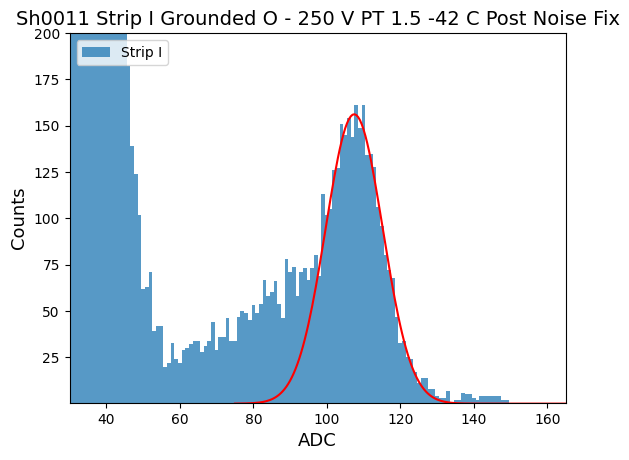

<Figure size 640x480 with 0 Axes>

In [37]:
plot_min = 20
plot_max = 150
ymin = 0.5
ymax = 200

#Gaussian fit, recall:
#  a: Some scaling factor to multiple the Gaussian by
#  b: Mean of the distribution
#  c: sigma of the distribution (square root of the variance), FWHM ~ 2.355*sigma
def gaussian(x, a, b, c):
    return a * np.exp(-((x - b)**2) / (2 * c**2))

y_scale = 1 #No scaling
title = txtname
plt.title(title,fontsize=14)
plt.xlabel("ADC",fontsize=13)
plt.ylabel("Counts",fontsize=13)
plt.ylim(ymin,ymax)
plt.xlim(Cshoulder_min*0.5,Xray_max*1.1)

Nhits = np.array(Nhits)*y_scale

#Attempt to fit Gaussian:
Cshoulder_min = 60
Cshoulder_max = 100
Xray_min = Cshoulder_max
Xray_max = 150
Xray_peak = 88 #keV X-rays
dx = 0.5

#I can see this is going to have to be an iterative process!!!

Xray_xvals = np.arange(0.75*Xray_min,1.25*Xray_max,dx)
x_fitpars, x_mat = curve_fit(gaussian, ADC[Xray_min:Xray_max], Nhits[Xray_min:Xray_max], p0=[Xray_min, Xray_max, 5])
Xray_yvals = gaussian(Xray_xvals,x_fitpars[0],x_fitpars[1],x_fitpars[2])


#CS_xvals = np.arange(0.75*Cshoulder_min,1.25*Cshoulder_max,dx)
#Xray_xvals = np.arange(0.75*Xray_min,1.25*Xray_max,dx)

#CS_fitpars, CS_mat = curve_fit(gaussian, ADC[Cshoulder_min:Cshoulder_max], Nhits[Cshoulder_min:Cshoulder_max], p0=[Cshoulder_min, Cshoulder_max, 5])
#CS_yvals = gaussian(CS_xvals,CS_fitpars[0],CS_fitpars[1],CS_fitpars[2])
#plt.plot(CS_xvals,CS_yvals,alpha=0.75,color='red')

#fitpars, mat = curve_fit(gaussian, ADC[Cshoulder_min:Cshoulder_max], Nhits[Cshoulder_min:Cshoulder_max], p0=[Cshoulder_min, Cshoulder_max, 5])

plt.bar(ADC[plot_min:plot_max], Nhits[plot_min:plot_max], 1, alpha=0.75,label=f"Strip {Strip}")
plt.plot(Xray_xvals,Xray_yvals,color='red')
plt.legend(loc = 'upper left')
plt.show()
savename = os.path.join(file_path,title+"test.png")
plt.savefig(savename) #Save the file

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0136 Post-Dice A2 F1 E -37 C 250 V/Sh0136 A2 250 V 5x -37 C RT 1 ADCCH-Count.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0136 Post-Dice A2 F1 E -37 C 250 V
16384
Strip A2 Mean: 116.94973308995117
Strip A2 FWHM: 5.204%, Err: 0.060%
Strip A2 FWHM: 4.579 keV, Err: 0.052 keV


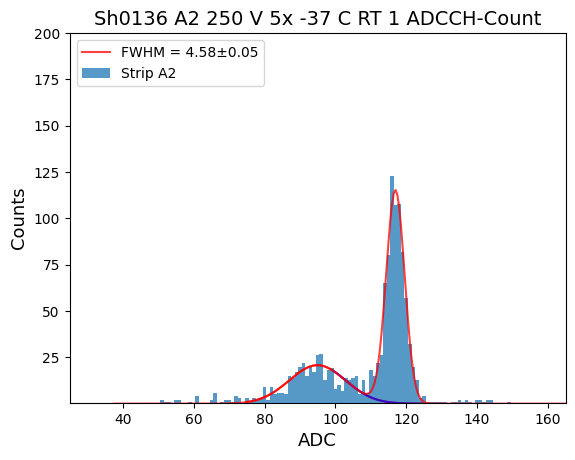

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0136 Post-Dice A2 F1 E -37 C 250 V/Sh0136 A2 250 V 5x -37 C RT 2 ADCCH-Count.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0136 Post-Dice A2 F1 E -37 C 250 V
16384
Strip A2 Mean: 116.01423944977778
Strip A2 FWHM: 4.210%, Err: 0.041%
Strip A2 FWHM: 3.705 keV, Err: 0.036 keV


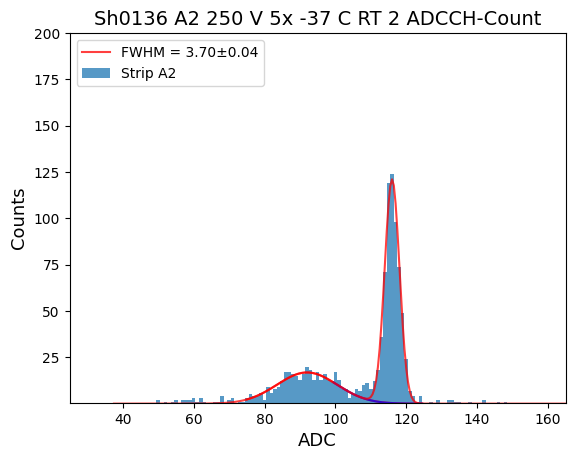

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0136 Post-Dice A2 F1 E -37 C 250 V/Sh0136 A2 250 V 5x -37 C RT 3 ADCCH-Count.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0136 Post-Dice A2 F1 E -37 C 250 V
16384
Strip A2 Mean: 115.84123407752884
Strip A2 FWHM: 3.833%, Err: 0.034%
Strip A2 FWHM: 3.373 keV, Err: 0.030 keV


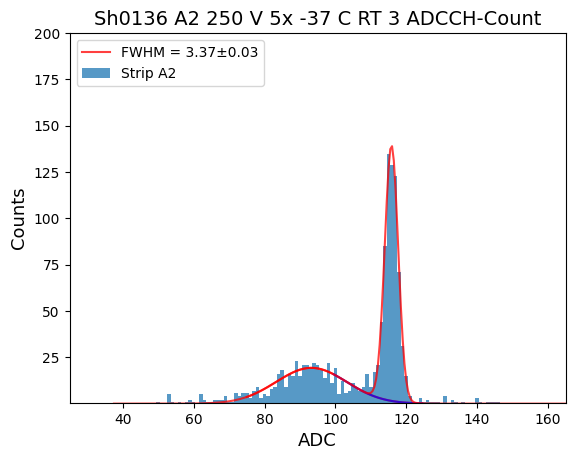

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0136 Post-Dice A2 F1 E -37 C 250 V/Sh0136 A2 250 V 5x -37 C RT 4 ADCCH-Count.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0136 Post-Dice A2 F1 E -37 C 250 V
16384
Strip A2 Mean: 115.79442301578716
Strip A2 FWHM: 4.330%, Err: 0.056%
Strip A2 FWHM: 3.810 keV, Err: 0.049 keV


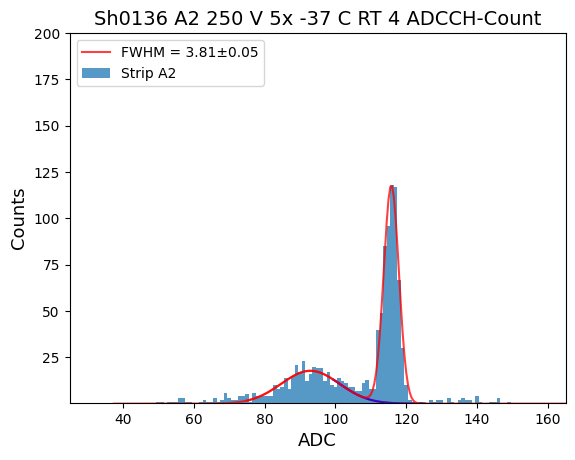

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0136 Post-Dice A2 F1 E -37 C 250 V/Sh0136 A2 250 V 5x -37 C RT 5 ADCCH-Count.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0136 Post-Dice A2 F1 E -37 C 250 V
16384
Strip A2 Mean: 115.54611501195029
Strip A2 FWHM: 4.396%, Err: 0.039%
Strip A2 FWHM: 3.868 keV, Err: 0.035 keV


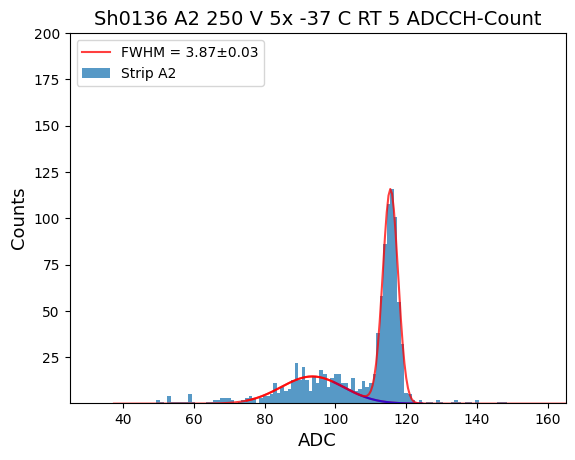

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0136 Post-Dice A2 F1 E -37 C 250 V/Sh0136 A2 250 V 5x -37 C RT 6 ADCCH-Count.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0136 Post-Dice A2 F1 E -37 C 250 V
16384
Strip A2 Mean: 115.43611095135677
Strip A2 FWHM: 4.754%, Err: 0.046%
Strip A2 FWHM: 4.184 keV, Err: 0.041 keV


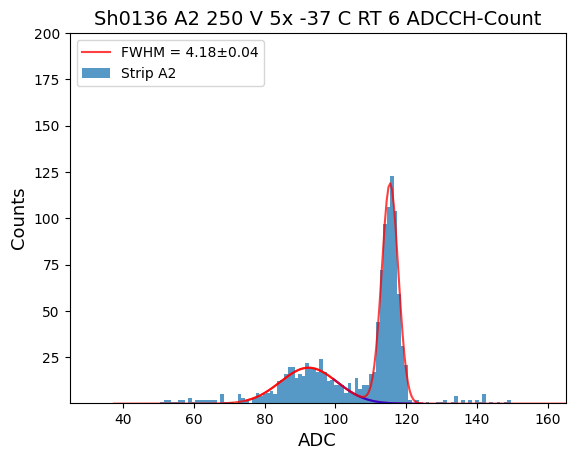

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0136 Post-Dice A2 F1 E -37 C 250 V/Sh0136 A2 250 V 5x -37 C RT 7 ADCCH-Count.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0136 Post-Dice A2 F1 E -37 C 250 V
16384
Strip A2 Mean: 115.40631903920563
Strip A2 FWHM: 4.355%, Err: 0.041%
Strip A2 FWHM: 3.832 keV, Err: 0.036 keV


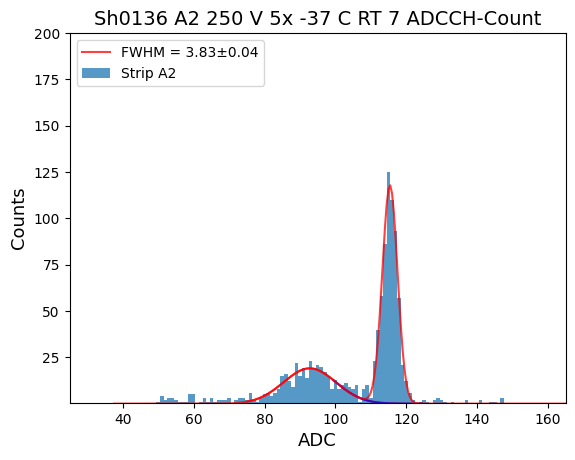

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0136 Post-Dice A2 F1 E -37 C 250 V/Sh0136 A2 250 V 5x -37 C RT 8 ADCCH-Count.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0136 Post-Dice A2 F1 E -37 C 250 V
16384
Strip A2 Mean: 114.95020201852327
Strip A2 FWHM: 5.212%, Err: 0.061%
Strip A2 FWHM: 4.587 keV, Err: 0.054 keV


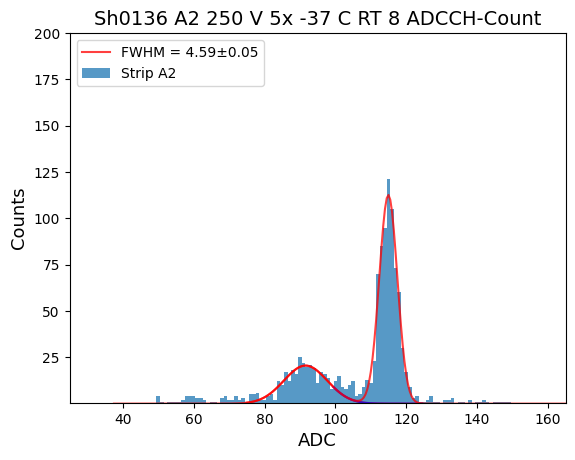

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0136 Post-Dice A2 F1 E -37 C 250 V/Sh0136 A2 250 V 5x -37 C RT 9 ADCCH-Count.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0136 Post-Dice A2 F1 E -37 C 250 V
16384
Strip A2 Mean: 115.16810991233116
Strip A2 FWHM: 5.082%, Err: 0.058%
Strip A2 FWHM: 4.472 keV, Err: 0.051 keV


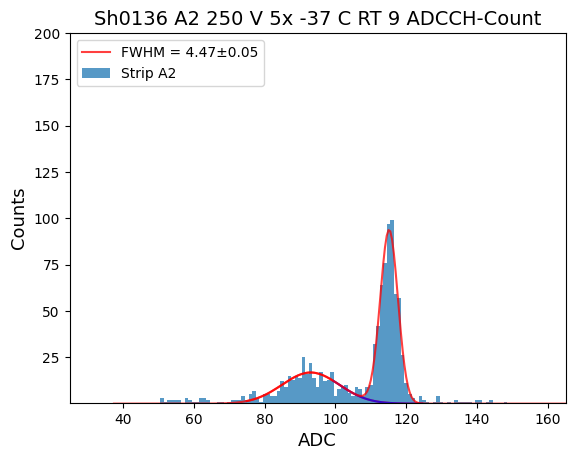

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0136 Post-Dice A2 F1 E -37 C 250 V/Sh0136 A2 250 V 5x -37 C RT 10 ADCCH-Count.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0136 Post-Dice A2 F1 E -37 C 250 V
16384
Strip A2 Mean: 115.28202184395076
Strip A2 FWHM: 5.333%, Err: 0.056%
Strip A2 FWHM: 4.693 keV, Err: 0.049 keV


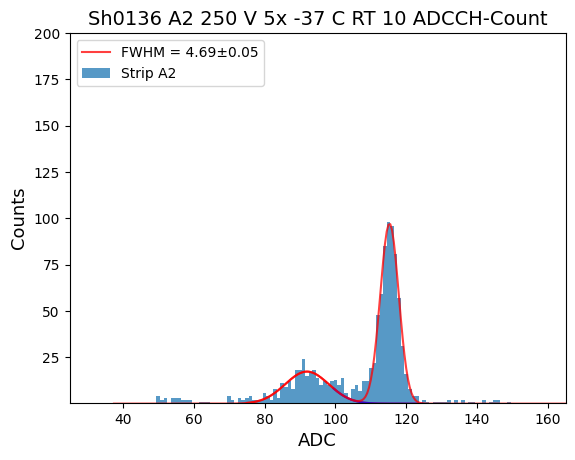

In [203]:
#Find file and store values

prename= r"/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0136 Post-Dice A2 F1 E -37 C 250 V"

Peaking_Time_Array = [1,2,3,4,5,6,7,8,9,10]
Strip = "A2"

plot_min = 50
plot_max = 150
ymin = 0.5
ymax = 200

#Gaussian fit, recall:
#  a: Some scaling factor to multiple the Gaussian by
#  b: Mean of the distribution
#  c: sigma of the distribution (square root of the variance), FWHM ~ 2.355*sigma
def gaussian(x, a, b, c):
    return a * np.exp(-((x - b)**2) / (2 * c**2))

Cshoulder_min = 50
Cshoulder_max = 100
Xray_min = Cshoulder_max
Xray_max = 150
Xray_peak = 88 #keV X-rays
dx = 0.5

#X values for the Gaussian, more "smooth" than the actual histogram
xvals = np.arange(0.75*Cshoulder_min,1.25*Cshoulder_max,dx)
Xray_xvals = np.arange(0.75*Xray_min,1.25*Xray_max,dx)


for k in range(len(Peaking_Time_Array)):
    PT = Peaking_Time_Array[k]
    txtname = f"Sh0136 {Strip} 250 V 5x -37 C RT {PT} ADCCH-Count"
    #txtname = f"Sh0786_{Strip} PT {PT}"

    file_path = os.path.join(prename)
    name = os.path.join(prename,txtname+".txt")
    filename = os.path.join(prename,txtname+".png")
    print(name)

    if os.path.exists(file_path):
        print(f"Path exists: {file_path}")
        pltfile = open(name, "r")
        nlines = len(open(name).readlines(  ))
        print(nlines)

        tarray = [0]*3
        ADC = [0]*nlines
        Nhits = [0]*nlines

        for i, x in enumerate(pltfile):
            if i == 0 or i == 1: #skip the first two lines
                continue
            tarray = x.strip().split(' ')
            ADC[i] = int(tarray[0])
            Nhits[i] = int(tarray[1])


    fitpars, mat = curve_fit(gaussian, ADC[Cshoulder_min:Cshoulder_max], Nhits[Cshoulder_min:Cshoulder_max], p0=[Cshoulder_min, Cshoulder_max, 5])
    #print(f'Strip {Strip}:' + str(fitpars))

    y_scale = 1 #No scaling
    title = txtname
    plt.title(title,fontsize=14)
    plt.xlabel("ADC",fontsize=13)
    plt.ylabel("Counts",fontsize=13)
    plt.ylim(ymin,ymax)
    plt.xlim(Cshoulder_min*0.5,Xray_max*1.1)

    Nhits = np.array(Nhits)*y_scale

    yvals = gaussian(xvals,fitpars[0],fitpars[1],fitpars[2])
    plt.plot(xvals,yvals,alpha=0.75,color='red')

    x_fitpars, x_mat = curve_fit(gaussian, ADC[Xray_min:Xray_max], Nhits[Xray_min:Xray_max], p0=[Xray_min, Xray_max, 5])

    indices = np.where(xvals >= Xray_min-dx)[0] #Compton shoulder xvals where there is overlap with Xray range
    plt.plot(xvals[indices],yvals[indices],alpha=0.75,color='blue')

    Xray_yvals = gaussian(Xray_xvals,x_fitpars[0],x_fitpars[1],x_fitpars[2])

    Nhits_CS_Subtracted = np.zeros(Xray_max)
    for i in range(Xray_min,Xray_max):
        Nhits_CS_Subtracted[i] = Nhits[i] - gaussian(i, fitpars[0],fitpars[1],fitpars[2])

    CS_sub_fitpars, CS_sub_mat = curve_fit(gaussian, ADC[Xray_min:Xray_max], Nhits_CS_Subtracted[Xray_min:Xray_max], p0=[Xray_min,Xray_max, 5])
    Xray_yvals_CS_sub = gaussian(Xray_xvals, fitpars[0],fitpars[1],fitpars[2]) + gaussian(Xray_xvals,CS_sub_fitpars[0],CS_sub_fitpars[1],CS_sub_fitpars[2])
    CS_sub_errors = np.sqrt(np.diag(CS_sub_mat))
    CS_sub_sigma = np.abs(CS_sub_fitpars[2])

    Nhits_CS_Subtracted = np.zeros(Xray_max)
    for i in range(Xray_min,Xray_max):
        Nhits_CS_Subtracted[i] = Nhits[i] - gaussian(i, fitpars[0],fitpars[1],fitpars[2])

    print(f'Strip {Strip} Mean: {CS_sub_fitpars[1]}')
    print(f'Strip {Strip} FWHM: {100*2.355*CS_sub_sigma/CS_sub_fitpars[1]:.3f}%, Err: {100*CS_sub_errors[2]/CS_sub_fitpars[1]:.3f}%')
    print(f'Strip {Strip} FWHM: {2.355*CS_sub_sigma*Xray_peak/CS_sub_fitpars[1]:.3f} keV, Err: {CS_sub_errors[2]*Xray_peak/CS_sub_fitpars[1]:.3f} keV')

    plt.bar(ADC[plot_min:plot_max], Nhits[plot_min:plot_max], 1, alpha=0.75,label=f"Strip {Strip}")
    plt.plot(Xray_xvals,Xray_yvals_CS_sub,alpha=0.75,color='red',label=f'FWHM = {2.355*CS_sub_sigma*Xray_peak/CS_sub_fitpars[1]:.2f}\u00B1{CS_sub_errors[2]*Xray_peak/CS_sub_fitpars[1]:.2f}')
    plt.legend(loc = 'upper left')
    savename = os.path.join(file_path,f"{Strip}_{PT}_test.png")
    plt.savefig(savename) #Save the file
    plt.show()


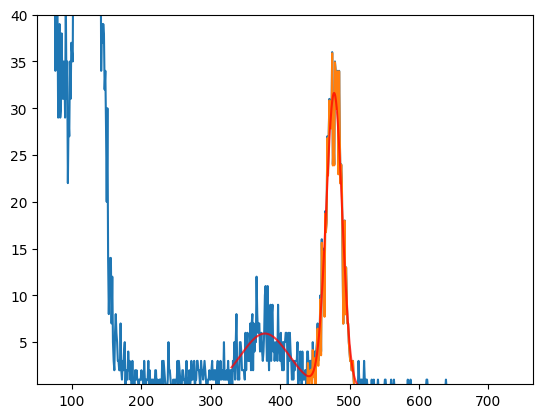

In [100]:
#Testing out the subtraction

Nhits_CS_Subtracted = np.zeros(Xray_max)
for i in range(Xray_min,Xray_max):
    Nhits_CS_Subtracted[i] = Nhits[i] - gaussian(i, fitpars[0],fitpars[1],fitpars[2])

CS_sub_fitpars, CS_sub_mat = curve_fit(gaussian, ADC[Xray_min:Xray_max], Nhits_CS_Subtracted[Xray_min:Xray_max], p0=[Xray_min,Xray_max, 5])
Xray_yvals_CS_sub = gaussian(Xray_xvals, fitpars[0],fitpars[1],fitpars[2]) + gaussian(Xray_xvals,CS_sub_fitpars[0],CS_sub_fitpars[1],CS_sub_fitpars[2])

plt.ylim(ymin,ymax)
plt.xlim(50,Xray_max*1.5)
plt.plot(Nhits)
plt.plot(Nhits_CS_Subtracted)
plt.plot(Xray_xvals,Xray_yvals_CS_sub,alpha=0.75,color='red')


Strip F1 Mean: 114.99431139360777
Strip F1 FWHM: 5.636%, Err: 0.095%
Strip F1 FWHM: 4.960 keV, Err: 0.084 keV


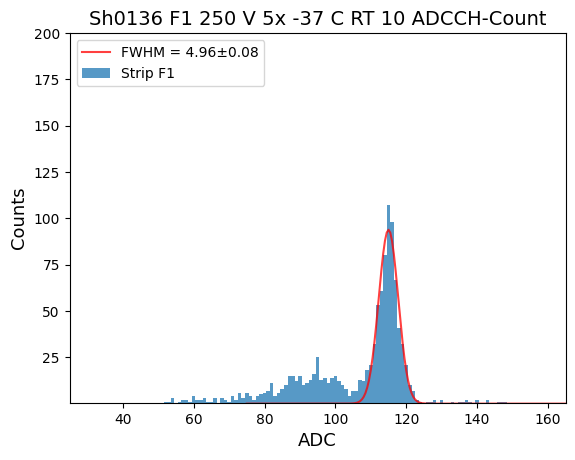

In [185]:
#Special case where "auto" fit isn't so good:
#No CS sub, just fit the peak!

prename= r"/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0136 Post-Dice A2 F1 E -37 C 250 V"

PT = 10
Strip = "F1"
txtname = f"Sh0136 {Strip} 250 V 5x -37 C RT {PT} ADCCH-Count"

plot_min = 50
plot_max = 150
ymin = 0.5
ymax = 200

#Gaussian fit, recall:
#  a: Some scaling factor to multiple the Gaussian by
#  b: Mean of the distribution
#  c: sigma of the distribution (square root of the variance), FWHM ~ 2.355*sigma
def gaussian(x, a, b, c):
    return a * np.exp(-((x - b)**2) / (2 * c**2))

Cshoulder_min = 50
Cshoulder_max = 100
Xray_min = Cshoulder_max
Xray_max = 150
Xray_peak = 88 #keV X-rays
dx = 0.5

#X values for the Gaussian, more "smooth" than the actual histogram
xvals = np.arange(0.75*Cshoulder_min,1.25*Cshoulder_max,dx)
Xray_xvals = np.arange(0.75*Xray_min,1.25*Xray_max,dx)

fitpars, mat = curve_fit(gaussian, ADC[Cshoulder_min:Cshoulder_max], Nhits[Cshoulder_min:Cshoulder_max], p0=[Cshoulder_min, Cshoulder_max, 5])
#print(f'Strip {Strip}:' + str(fitpars))

y_scale = 1 #No scaling
title = txtname
plt.title(title,fontsize=14)
plt.xlabel("ADC",fontsize=13)
plt.ylabel("Counts",fontsize=13)
plt.ylim(ymin,ymax)
plt.xlim(Cshoulder_min*0.5,Xray_max*1.1)

Nhits = np.array(Nhits)*y_scale

yvals = gaussian(xvals,fitpars[0],fitpars[1],fitpars[2])
#plt.plot(xvals,yvals,alpha=0.75,color='red')

x_fitpars, x_mat = curve_fit(gaussian, ADC[Xray_min:Xray_max], Nhits[Xray_min:Xray_max], p0=[Xray_min, Xray_max, 5])
x_errors = np.sqrt(np.diag(x_mat))

indices = np.where(xvals >= Xray_min-dx)[0] #Compton shoulder xvals where there is overlap with Xray range
#plt.plot(xvals[indices],yvals[indices],alpha=0.75,color='blue')

Xray_yvals = gaussian(Xray_xvals,x_fitpars[0],x_fitpars[1],x_fitpars[2])
x_sigma = np.abs(x_fitpars[2])

#plt.plot(Xray_xvals,Xray_yvals,alpha=0.75,color='blue')

print(f'Strip {Strip} Mean: {x_fitpars[1]}')
print(f'Strip {Strip} FWHM: {100*2.355*x_sigma/x_fitpars[1]:.3f}%, Err: {100*x_errors[2]/x_fitpars[1]:.3f}%')
print(f'Strip {Strip} FWHM: {2.355*x_sigma*Xray_peak/x_fitpars[1]:.3f} keV, Err: {x_errors[2]*Xray_peak/x_fitpars[1]:.3f} keV')

plt.bar(ADC[plot_min:plot_max], Nhits[plot_min:plot_max], 1, alpha=0.75,label=f"Strip {Strip}")
plt.plot(Xray_xvals,Xray_yvals,alpha=0.75,color='red',label=f'FWHM = {2.355*x_sigma*Xray_peak/x_fitpars[1]:.2f}\u00B1{x_errors[2]*Xray_peak/x_fitpars[1]:.2f}')
plt.legend(loc = 'upper left')
savename = os.path.join(file_path,f"{Strip}_{PT}_non_auto_test.png")
plt.savefig(savename) #Save the file
plt.show()

11	stripI	1000.00	23.13	0.38
11	stripI	1500.00	14.95	0.12
11	stripI	2000.00	13.91	0.19
11	stripI	3000.00	12.75	0.20
11	stripI	3500.00	12.36	0.24
11	stripI	4000.00	11.86	0.16
11	stripI	4500.00	11.31	0.15
11	stripI	5000.00	10.89	0.17
11	stripI	6000.00	12.08	0.18
11	stripI	6500.00	10.94	0.30
11	stripI	7000.00	13.47	0.28
11	stripI	8000.00	13.06	0.31
11	stripI	9000.00	15.05	0.35
11	stripI	10000.00	13.45	0.30


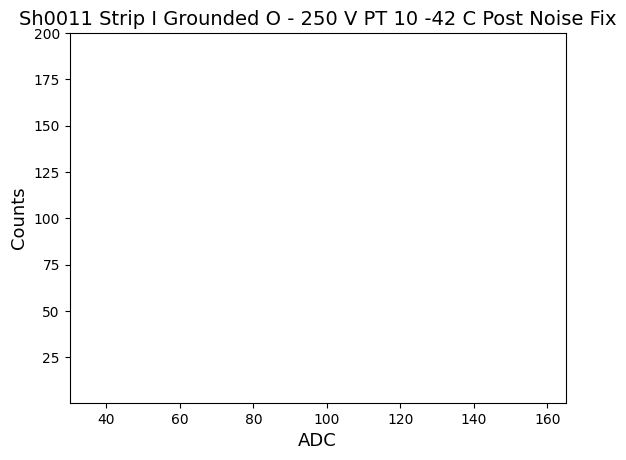

In [50]:
#Just the Gaussian!

prename= r"/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0011 5x Output Post-Etch Post KMWP Noise Wizardry 8-27-2026"


#Peaking_Time_Array = [1,1.5]
Peaking_Time_Array = [1,1.5,2,3,3.5,4,4.5,5,6,6.5,7,8,9,10]
Strip = "I"
det = 11

plot_min = 30
plot_max = 150
ymin = 0.5
ymax = 200

#Gaussian fit, recall:
#  a: Some scaling factor to multiple the Gaussian by
#  b: Mean of the distribution
#  c: sigma of the distribution (square root of the variance), FWHM ~ 2.355*sigma
def gaussian(x, a, b, c):
    return a * np.exp(-((x - b)**2) / (2 * c**2))

y_scale = 1 #No scaling
title = txtname
plt.title(title,fontsize=14)
plt.xlabel("ADC",fontsize=13)
plt.ylabel("Counts",fontsize=13)
plt.ylim(ymin,ymax)
plt.xlim(Cshoulder_min*0.5,Xray_max*1.1)

Nhits = np.array(Nhits)*y_scale

#Attempt to fit Gaussian:
Cshoulder_min = 60
Cshoulder_max = 100
Xray_min = Cshoulder_max
Xray_max = 150
Xray_peak = 88 #keV X-rays
dx = 0.5

#X values for the Gaussian, more "smooth" than the actual histogram
xvals = np.arange(0.75*Cshoulder_min,1.25*Cshoulder_max,dx)
Xray_xvals = np.arange(0.75*Xray_min,1.25*Xray_max,dx)


for k in range(len(Peaking_Time_Array)):
    PT = Peaking_Time_Array[k]
    txtname = f"Sh0011 Strip {Strip} Grounded O - 250 V PT {PT} -42 C Post Noise Fix"
    #txtname = f"Sh0786_{Strip} PT {PT}"

    file_path = os.path.join(prename)
    name = os.path.join(prename,txtname+".txt")
    filename = os.path.join(prename,txtname+".png")
    #print(name)

    if os.path.exists(file_path):
        #print(f"Path exists: {file_path}")
        pltfile = open(name, "r")
        nlines = len(open(name).readlines(  ))
        #print(nlines)

        tarray = [0]*3
        ADC = [0]*nlines
        Nhits = [0]*nlines

        for i, x in enumerate(pltfile):
            if i == 0 or i == 1: #skip the first two lines
                continue
            tarray = x.strip().split(' ')
            ADC[i] = int(tarray[0])
            Nhits[i] = int(tarray[1])

    Xray_xvals = np.arange(0.75*Xray_min,1.25*Xray_max,dx)
    x_fitpars, x_mat = curve_fit(gaussian, ADC[Xray_min:Xray_max], Nhits[Xray_min:Xray_max], p0=[Xray_min, Xray_max, 5])
    Xray_yvals = gaussian(Xray_xvals,x_fitpars[0],x_fitpars[1],x_fitpars[2])
    x_errors = np.sqrt(np.diag(x_mat))
    x_sigma = np.abs(x_fitpars[2])

    '''
    y_scale = 1 #No scaling
    title = txtname
    plt.title(title,fontsize=14)
    plt.xlabel("ADC",fontsize=13)
    plt.ylabel("Counts",fontsize=13)
    plt.ylim(ymin,ymax)
    plt.xlim(Cshoulder_min*0.5,Xray_max*1.1)

    print(f'Strip {Strip} Mean: {x_fitpars[1]}')
    print(f'Strip {Strip} FWHM: {100*2.355*x_sigma/x_fitpars[1]:.3f}%, Err: {100*x_errors[2]/x_fitpars[1]:.3f}%')
    print(f'Strip {Strip} FWHM: {2.355*x_sigma*Xray_peak/x_fitpars[1]:.3f} keV, Err: {x_errors[2]*Xray_peak/x_fitpars[1]:.3f} keV')
    '''

    #plt.bar(ADC[plot_min:plot_max], Nhits[plot_min:plot_max], 1, alpha=0.75,label=f"Strip {Strip}")
    #plt.plot(Xray_xvals,Xray_yvals,alpha=0.75,color='red',label=f'FWHM = {2.355*x_sigma*Xray_peak/x_fitpars[1]:.2f}\u00B1{x_errors[2]*Xray_peak/x_fitpars[1]:.2f}')
    #plt.legend(loc = 'upper left')
    #savename = os.path.join(file_path,f"{Strip}_{PT}_test.png")
    #plt.savefig(savename) #Save the file
    #plt.show()
    print(f"{det}\tstrip{Strip}\t{1000*PT:.2f}\t{2.355*x_sigma*Xray_peak/x_fitpars[1]:.2f}\t{x_errors[2]*Xray_peak/x_fitpars[1]:.2f}")



stripA2
stripF1
stripE


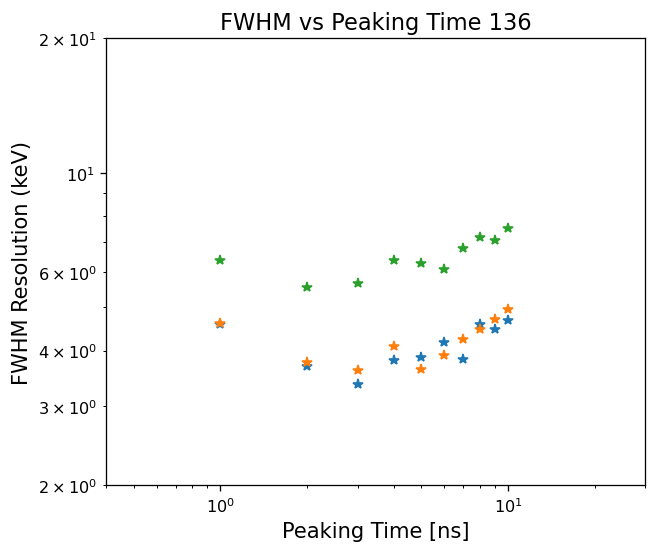

In [321]:
import pandas as pd
from collections import Counter

datfile = os.path.join(prename,'summary_KYfit.dat')
df = pd.read_csv(datfile, sep='\t', header=None)
nlines = len(df) #number of lines in the file
strip_list = list(set(df.head(nlines)[:][1])) #Individual strip names
nstrips = len(strip_list)

#What's the best way to do this? Associate each point with a strip/plot, something robust
#Check each line for the Strip name and put the numbers in the associated FWHM and errors array

#Below, use the .head()[column][row] function to pull specific values.
#[0] detector number, [1] strip letter, [2] PT in ns, [3] FWHM in keV, [4] error in FWHM
#print(df.head(nlines)[:][1])
#print(strip_list)

plt.figure(figsize=(6, 5),dpi=116)
plt.xscale('log')
plt.yscale('log')
plt.xlabel("Peaking Time [ns]",fontsize=13)
plt.ylabel("FWHM Resolution (keV)",fontsize=13)
plt.title(f'FWHM vs Peaking Time {det}',fontsize=14)
plt.ylim(2,20)
plt.xlim(0.4,30)

tarray = [0]*5 #Dat file structure has 5 lines

#Go line by line through the file, check the strip name, associate it with strip, right now I just want the FWHM and PT values!

for strp in strip_list:
    #Need to open this to be read each time!
    pltfile = open(datfile, "r")
    print(strp)
    FWHM = []
    PT = []
    #Go through the entire file
    for i, x in enumerate(pltfile):
        tarray = x.strip().split('\t')
        if(tarray[1] == strp):
            #print(f'PT: {tarray[2]} and FWHM {tarray[3]}')
            PT.append(float(tarray[2])/1000)
            FWHM.append(float(tarray[3]))
    plt.plot(PT,FWHM,'*')

    

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0011 5x Output Post-Etch Post KMWP Noise Wizardry 8-27-2026/Sh0011 Strip I Grounded O - 250 V PT 1 -42 C Post Noise Fix.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0011 5x Output Post-Etch Post KMWP Noise Wizardry 8-27-2026
16384
Strip I Mean: 105.75780178912008
Strip I FWHM: 26.289%, Err: 0.433%
Strip I FWHM: 23.134 keV, Err: 0.381 keV


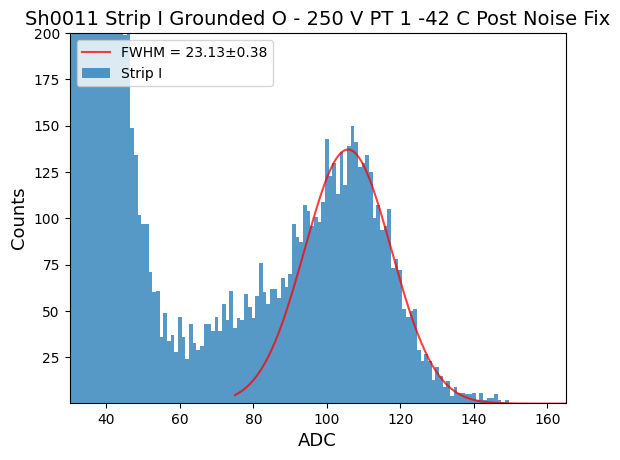

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0011 5x Output Post-Etch Post KMWP Noise Wizardry 8-27-2026/Sh0011 Strip I Grounded O - 250 V PT 1.5 -42 C Post Noise Fix.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0011 5x Output Post-Etch Post KMWP Noise Wizardry 8-27-2026
16384
Strip I Mean: 107.44373594119584
Strip I FWHM: 16.990%, Err: 0.136%
Strip I FWHM: 14.951 keV, Err: 0.120 keV


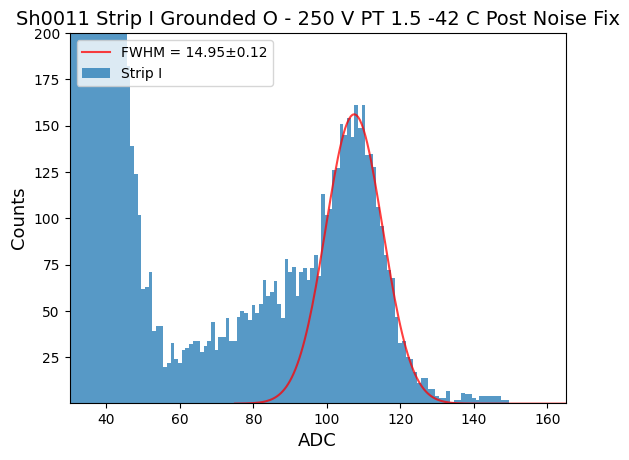

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0011 5x Output Post-Etch Post KMWP Noise Wizardry 8-27-2026/Sh0011 Strip I Grounded O - 250 V PT 2 -42 C Post Noise Fix.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0011 5x Output Post-Etch Post KMWP Noise Wizardry 8-27-2026
16384
Strip I Mean: 106.88084911205492
Strip I FWHM: 15.809%, Err: 0.219%
Strip I FWHM: 13.912 keV, Err: 0.193 keV


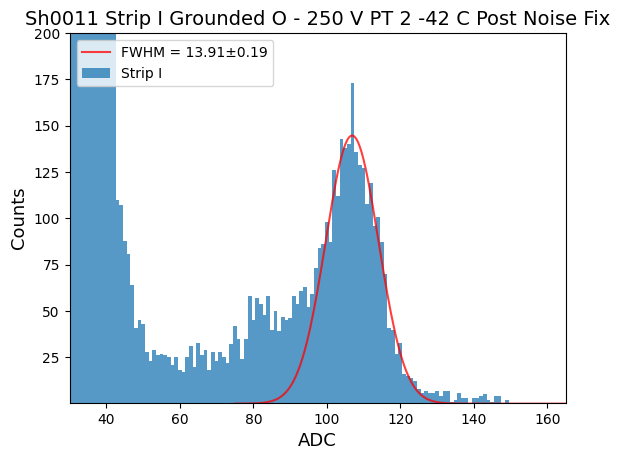

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0011 5x Output Post-Etch Post KMWP Noise Wizardry 8-27-2026/Sh0011 Strip I Grounded O - 250 V PT 3 -42 C Post Noise Fix.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0011 5x Output Post-Etch Post KMWP Noise Wizardry 8-27-2026
16384
Strip I Mean: 107.07635202181302
Strip I FWHM: 14.492%, Err: 0.226%
Strip I FWHM: 12.753 keV, Err: 0.199 keV


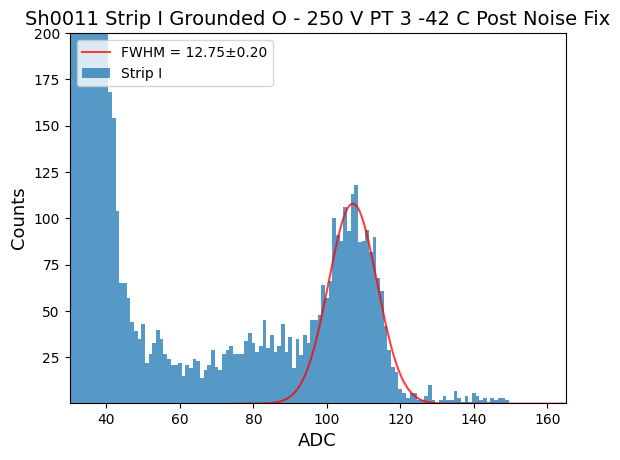

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0011 5x Output Post-Etch Post KMWP Noise Wizardry 8-27-2026/Sh0011 Strip I Grounded O - 250 V PT 3.5 -42 C Post Noise Fix.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0011 5x Output Post-Etch Post KMWP Noise Wizardry 8-27-2026
16384
Strip I Mean: 106.54726342678063
Strip I FWHM: 14.049%, Err: 0.268%
Strip I FWHM: 12.363 keV, Err: 0.236 keV


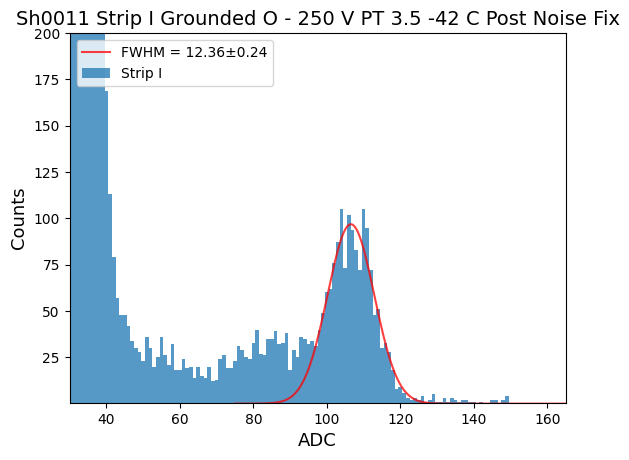

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0011 5x Output Post-Etch Post KMWP Noise Wizardry 8-27-2026/Sh0011 Strip I Grounded O - 250 V PT 4 -42 C Post Noise Fix.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0011 5x Output Post-Etch Post KMWP Noise Wizardry 8-27-2026
16384
Strip I Mean: 106.68867352503229
Strip I FWHM: 13.482%, Err: 0.177%
Strip I FWHM: 11.864 keV, Err: 0.156 keV


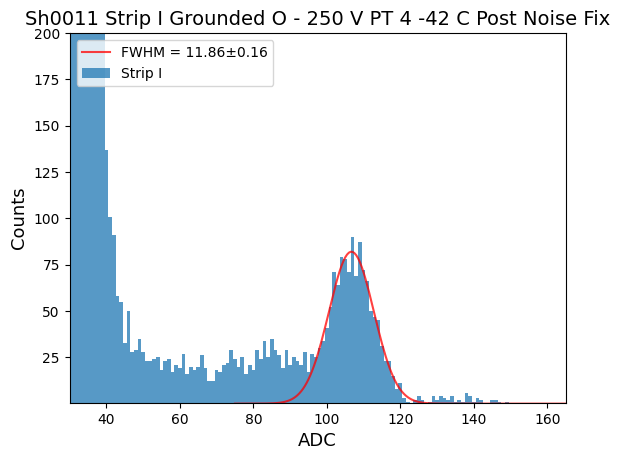

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0011 5x Output Post-Etch Post KMWP Noise Wizardry 8-27-2026/Sh0011 Strip I Grounded O - 250 V PT 4.5 -42 C Post Noise Fix.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0011 5x Output Post-Etch Post KMWP Noise Wizardry 8-27-2026
16384
Strip I Mean: 107.41956167575621
Strip I FWHM: 12.849%, Err: 0.170%
Strip I FWHM: 11.307 keV, Err: 0.149 keV


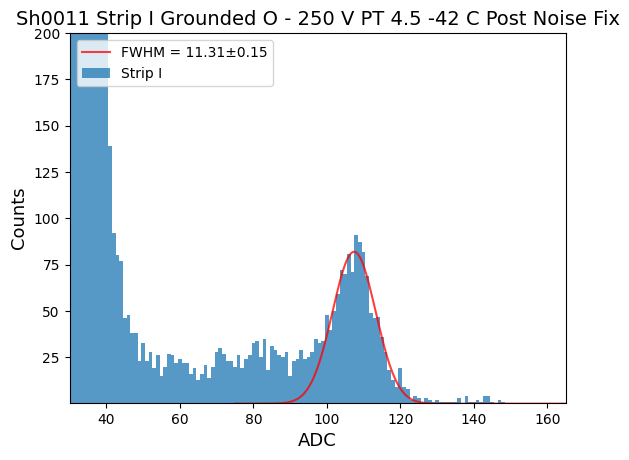

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0011 5x Output Post-Etch Post KMWP Noise Wizardry 8-27-2026/Sh0011 Strip I Grounded O - 250 V PT 5 -42 C Post Noise Fix.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0011 5x Output Post-Etch Post KMWP Noise Wizardry 8-27-2026
16384
Strip I Mean: 106.96967939232981
Strip I FWHM: 12.379%, Err: 0.190%
Strip I FWHM: 10.893 keV, Err: 0.167 keV


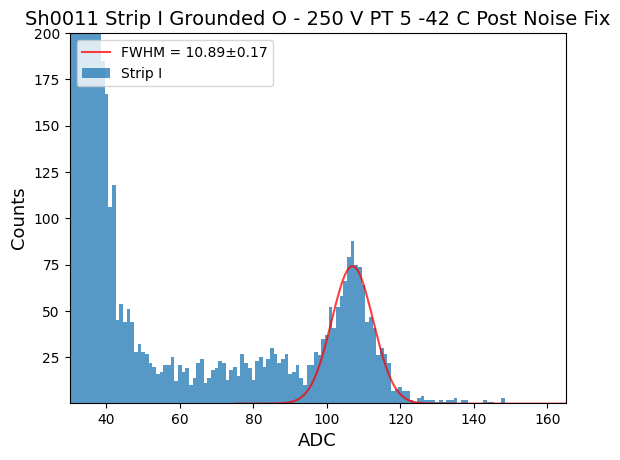

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0011 5x Output Post-Etch Post KMWP Noise Wizardry 8-27-2026/Sh0011 Strip I Grounded O - 250 V PT 6 -42 C Post Noise Fix.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0011 5x Output Post-Etch Post KMWP Noise Wizardry 8-27-2026
16384
Strip I Mean: 107.18692388442598
Strip I FWHM: 13.725%, Err: 0.206%
Strip I FWHM: 12.078 keV, Err: 0.181 keV


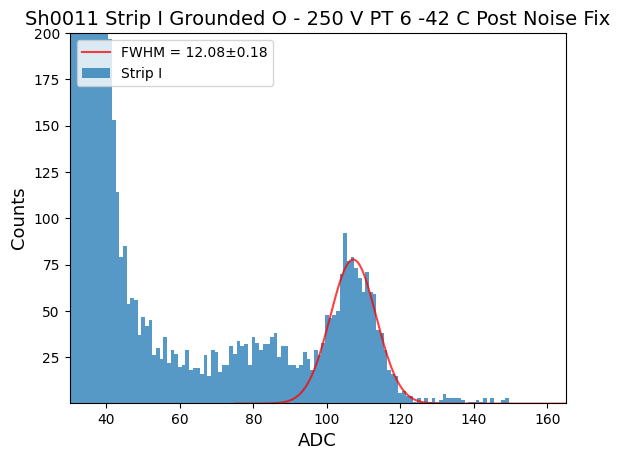

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0011 5x Output Post-Etch Post KMWP Noise Wizardry 8-27-2026/Sh0011 Strip I Grounded O - 250 V PT 6.5 -42 C Post Noise Fix.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0011 5x Output Post-Etch Post KMWP Noise Wizardry 8-27-2026
16384
Strip I Mean: 107.04253927767152
Strip I FWHM: 12.437%, Err: 0.339%
Strip I FWHM: 10.944 keV, Err: 0.298 keV


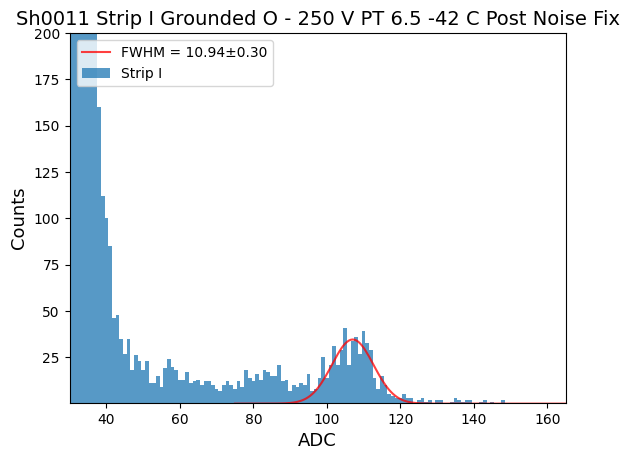

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0011 5x Output Post-Etch Post KMWP Noise Wizardry 8-27-2026/Sh0011 Strip I Grounded O - 250 V PT 7 -42 C Post Noise Fix.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0011 5x Output Post-Etch Post KMWP Noise Wizardry 8-27-2026
16384
Strip I Mean: 106.53338070565272
Strip I FWHM: 15.307%, Err: 0.320%
Strip I FWHM: 13.470 keV, Err: 0.282 keV


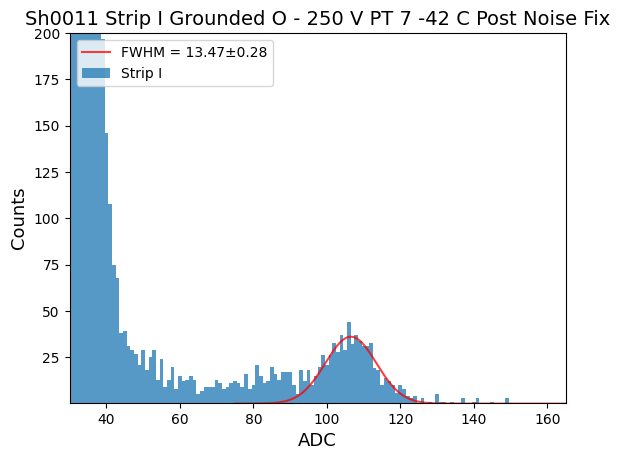

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0011 5x Output Post-Etch Post KMWP Noise Wizardry 8-27-2026/Sh0011 Strip I Grounded O - 250 V PT 8 -42 C Post Noise Fix.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0011 5x Output Post-Etch Post KMWP Noise Wizardry 8-27-2026
16384
Strip I Mean: 107.27537715308671
Strip I FWHM: 14.840%, Err: 0.348%
Strip I FWHM: 13.059 keV, Err: 0.306 keV


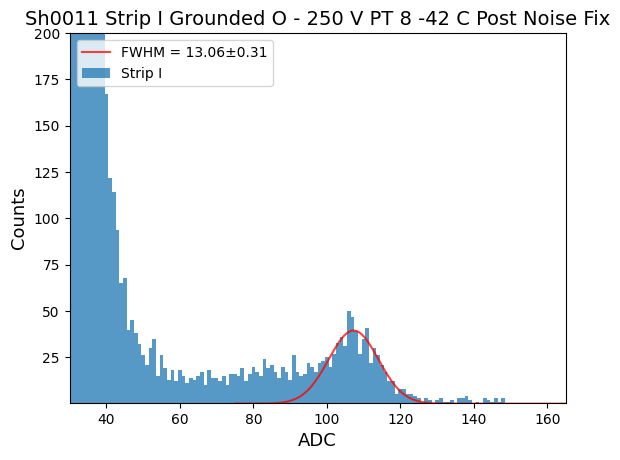

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0011 5x Output Post-Etch Post KMWP Noise Wizardry 8-27-2026/Sh0011 Strip I Grounded O - 250 V PT 9 -42 C Post Noise Fix.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0011 5x Output Post-Etch Post KMWP Noise Wizardry 8-27-2026
16384
Strip I Mean: 107.8975084473027
Strip I FWHM: 17.100%, Err: 0.401%
Strip I FWHM: 15.048 keV, Err: 0.353 keV


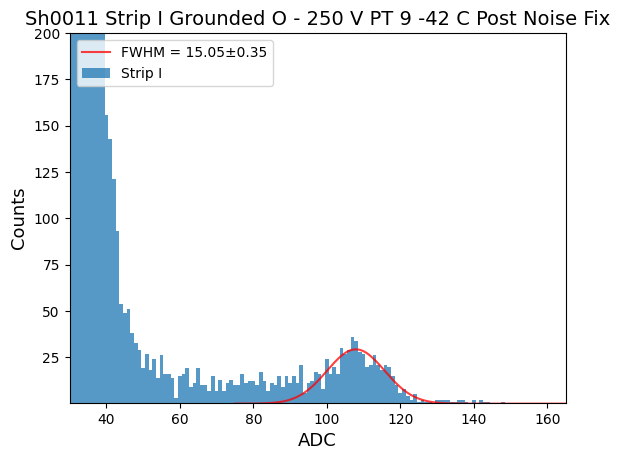

/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0011 5x Output Post-Etch Post KMWP Noise Wizardry 8-27-2026/Sh0011 Strip I Grounded O - 250 V PT 10 -42 C Post Noise Fix.txt
Path exists: /home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0011 5x Output Post-Etch Post KMWP Noise Wizardry 8-27-2026
16384
Strip I Mean: 107.73803821912132
Strip I FWHM: 15.289%, Err: 0.341%
Strip I FWHM: 13.455 keV, Err: 0.300 keV


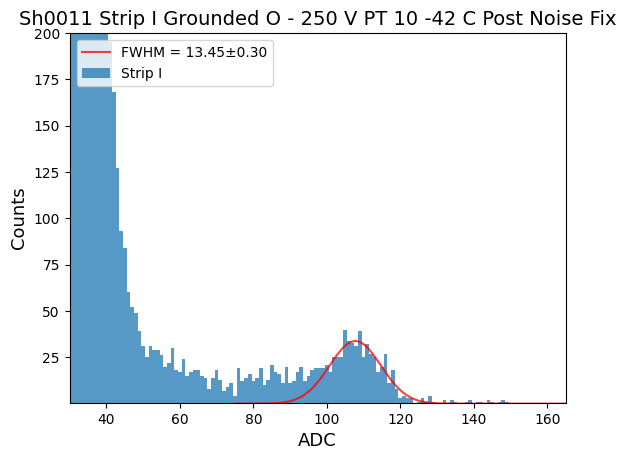

In [45]:
#Just the Gaussian!

prename= r"/home/kelsey/GitScripts/ActiveScripts/Python/Energy Resolution X-Rays/Sh0011 5x Output Post-Etch Post KMWP Noise Wizardry 8-27-2026"


#Peaking_Time_Array = [1,1.5]
Peaking_Time_Array = [1,1.5,2,3,3.5,4,4.5,5,6,6.5,7,8,9,10]
Strip = "I"

plot_min = 30
plot_max = 150
ymin = 0.5
ymax = 200

#Gaussian fit, recall:
#  a: Some scaling factor to multiple the Gaussian by
#  b: Mean of the distribution
#  c: sigma of the distribution (square root of the variance), FWHM ~ 2.355*sigma
def gaussian(x, a, b, c):
    return a * np.exp(-((x - b)**2) / (2 * c**2))

y_scale = 1 #No scaling
title = txtname
plt.title(title,fontsize=14)
plt.xlabel("ADC",fontsize=13)
plt.ylabel("Counts",fontsize=13)
plt.ylim(ymin,ymax)
plt.xlim(Cshoulder_min*0.5,Xray_max*1.1)

Nhits = np.array(Nhits)*y_scale

#Attempt to fit Gaussian:
Cshoulder_min = 60
Cshoulder_max = 100
Xray_min = Cshoulder_max
Xray_max = 150
Xray_peak = 88 #keV X-rays
dx = 0.5

#X values for the Gaussian, more "smooth" than the actual histogram
xvals = np.arange(0.75*Cshoulder_min,1.25*Cshoulder_max,dx)
Xray_xvals = np.arange(0.75*Xray_min,1.25*Xray_max,dx)


for k in range(len(Peaking_Time_Array)):
    PT = Peaking_Time_Array[k]
    txtname = f"Sh0011 Strip {Strip} Grounded O - 250 V PT {PT} -42 C Post Noise Fix"
    #txtname = f"Sh0786_{Strip} PT {PT}"

    file_path = os.path.join(prename)
    name = os.path.join(prename,txtname+".txt")
    filename = os.path.join(prename,txtname+".png")
    print(name)

    if os.path.exists(file_path):
        print(f"Path exists: {file_path}")
        pltfile = open(name, "r")
        nlines = len(open(name).readlines(  ))
        print(nlines)

        tarray = [0]*3
        ADC = [0]*nlines
        Nhits = [0]*nlines

        for i, x in enumerate(pltfile):
            if i == 0 or i == 1: #skip the first two lines
                continue
            tarray = x.strip().split(' ')
            ADC[i] = int(tarray[0])
            Nhits[i] = int(tarray[1])

    Xray_xvals = np.arange(0.75*Xray_min,1.25*Xray_max,dx)
    x_fitpars, x_mat = curve_fit(gaussian, ADC[Xray_min:Xray_max], Nhits[Xray_min:Xray_max], p0=[Xray_min, Xray_max, 5])
    Xray_yvals = gaussian(Xray_xvals,x_fitpars[0],x_fitpars[1],x_fitpars[2])
    x_errors = np.sqrt(np.diag(x_mat))
    x_sigma = np.abs(x_fitpars[2])
    
    y_scale = 1 #No scaling
    title = txtname
    plt.title(title,fontsize=14)
    plt.xlabel("ADC",fontsize=13)
    plt.ylabel("Counts",fontsize=13)
    plt.ylim(ymin,ymax)
    plt.xlim(Cshoulder_min*0.5,Xray_max*1.1)

    print(f'Strip {Strip} Mean: {x_fitpars[1]}')
    print(f'Strip {Strip} FWHM: {100*2.355*x_sigma/x_fitpars[1]:.3f}%, Err: {100*x_errors[2]/x_fitpars[1]:.3f}%')
    print(f'Strip {Strip} FWHM: {2.355*x_sigma*Xray_peak/x_fitpars[1]:.3f} keV, Err: {x_errors[2]*Xray_peak/x_fitpars[1]:.3f} keV')

    plt.bar(ADC[plot_min:plot_max], Nhits[plot_min:plot_max], 1, alpha=0.75,label=f"Strip {Strip}")
    plt.plot(Xray_xvals,Xray_yvals,alpha=0.75,color='red',label=f'FWHM = {2.355*x_sigma*Xray_peak/x_fitpars[1]:.2f}\u00B1{x_errors[2]*Xray_peak/x_fitpars[1]:.2f}')
    plt.legend(loc = 'upper left')
    savename = os.path.join(file_path,f"{Strip}_{PT}_test.png")
    plt.savefig(savename) #Save the file
    plt.show()

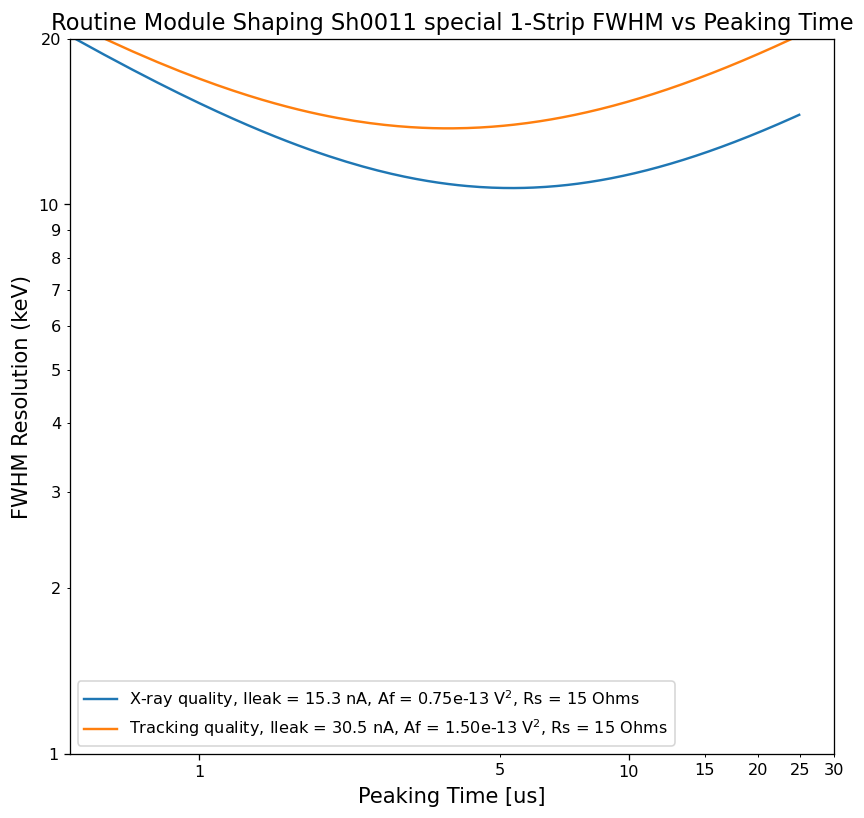

In [68]:
#What if plot noies model with standard parameters?
#Just copy the fitting thing lol

#Plotting below

f1 = plt.figure(figsize=(8.5,8),dpi=116)
ax1 = plt.gca()

ax1.semilogx()
ax1.semilogy()
ax1.set_xlabel("Peaking Time [us]",fontsize=13)
ax1.set_ylabel("FWHM Resolution (keV)",fontsize=13)
ax1.set_title(f'Routine Module Shaping Sh0011 special 1-Strip FWHM vs Peaking Time',fontsize=14)
ax1.set_ylim(1,20)
ax1.set_xlim(0.5,30)
ax1.xaxis.set_major_formatter(ScalarFormatter())
ax1.xaxis.set_minor_formatter(ScalarFormatter())
ax1.xaxis.set_minor_locator(MultipleLocator(5))
ax1.xaxis.set_major_formatter('{x:.0f}')
ax1.xaxis.set_minor_formatter('{x:.0f}')

ax1.yaxis.set_major_formatter(ScalarFormatter())
ax1.yaxis.set_minor_formatter(ScalarFormatter())
ax1.yaxis.set_major_formatter('{x:.0f}')
ax1.yaxis.set_minor_formatter('{x:.0f}')

q = 1.6e-19 #electron charge
k = 1.38e-23 #Bolzmann constant
eps = 3.6 #ionization energy of silicon
Rp = 100e6 #parallel resistance of preamp
gm = 18e-3 #transconductanct in FET ?Differrent than the paper says?
Bita = 1 #Not sure what this is yet
factor = (2.355*eps*1e-3/q); #Factor from ENC to FWHM
pi = 3.14159

Fi = 0.45;
Fv = 1.02;
Fvf = 0.52;

PT = np.arange(0.4, 25.0, 0.1)
PT = PT*10**-6

#Standard X-ray quality
Ileak = 6.1*2.5e-9
Af = 0.75e-13
Rs = 15
Cstrip = 6.1*38 #pF 8-strip is ~38 pF
Cothers = 30 #CFET = 10 pF, Cstrap + Cint = 20 pF
Ctot = (Cstrip + Cothers)*10**-12

T_Celsius = -37
T = (T_Celsius + 273)

enc_sq_std = (2*q*Ileak + 4*k*T/Rp)*Fi*PT + 4*k*T*Ctot**2*(Rs + Bita/gm)*Fv/PT + 2*pi*Af*Ctot**2*Fvf
FWHM_std = factor*np.sqrt(enc_sq_std)

ax1.plot(PT*10**6, FWHM_std,label = f"X-ray quality, Ileak = {Ileak*10**9:.1f} nA, Af = {Af*10**13:.2f}e-13 V$^2$, Rs = 15 Ohms")

#Standard tracking quality
Ileak = 6.1*5e-9
Af = 1.5e-13
Rs = 15

enc_sq_tracking = (2*q*Ileak + 4*k*T/Rp)*Fi*PT + 4*k*T*Ctot**2*(Rs + Bita/gm)*Fv/PT + 2*pi*Af*Ctot**2*Fvf
FWHM_tracking = factor*np.sqrt(enc_sq_tracking)

ax1.plot(PT*10**6, FWHM_tracking, label = f"Tracking quality, Ileak = {Ileak*10**9:.1f} nA, Af = {Af*10**13:.2f}e-13 V$^2$, Rs = 15 Ohms")

ax1.legend(loc='lower left')

savename = os.path.join(file_path,f"Eres_Plot_Sh0011.png")
plt.savefig(savename) #Save the file